# Brandt egg collections over time

Run all cells to count the **eggs** in records whose `Collector` field contains “Brandt” (case insensitive). Each record contributes its `Individual Count`, rather than counting one record as one egg. The chart shows annual totals across the full collection period, with zeroes for intervening years that have no matching records. The PNG is saved next to the input CSV.

The CSV is expected at the `G:` drive path below. If you move it, edit `CSV_PATH` in the first code cell. A complete date in `date collected m/d/y` supplies the year only when `year` is missing; day-only values in that column are ignored.


In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = Path(r"G:\My Drive\Egg Slip Scanning\EggSlipReorganizationProject_FULL.xlsx - Full List.csv")
OUTPUT_PATH = CSV_PATH.with_name("Brandt_eggs_collected_by_year.png")

if not CSV_PATH.is_file():
    raise FileNotFoundError(f"CSV not found: {CSV_PATH}\nEdit CSV_PATH above if the file has moved.")


In [3]:
# Read only the fields needed for this graph; keep text intact until it is validated.
columns = ["Collector", "Individual Count", "year", "date collected m/d/y"]
df = pd.read_csv(CSV_PATH, usecols=columns, dtype="string", encoding="utf-8-sig")

brandt = df.loc[df["Collector"].str.contains("Brandt", case=False, na=False)].copy()
if brandt.empty:
    raise ValueError("No rows have 'Brandt' in Collector. Check the CSV and collector spelling.")

# The 'year' column is authoritative where present. Some rows may instead have
# a complete m/d/Y or ISO date; a lone day number (like '4') is not a year.
numeric_year = pd.to_numeric(brandt["year"].str.strip(), errors="coerce")
numeric_year = numeric_year.where(numeric_year.eq(numeric_year.round()))
full_date = brandt["date collected m/d/y"].str.strip()
fallback_year = pd.to_datetime(full_date, format="%m/%d/%Y", errors="coerce").dt.year
fallback_year = fallback_year.fillna(
    pd.to_datetime(full_date, format="%Y-%m-%d", errors="coerce").dt.year
)
brandt["collection_year"] = numeric_year.fillna(fallback_year)
brandt["egg_count"] = pd.to_numeric(
    brandt["Individual Count"].str.replace(",", "", regex=False).str.strip(),
    errors="coerce",
)

valid_year = brandt["collection_year"].between(1700, pd.Timestamp.today().year).fillna(False)
valid_count = (
    brandt["egg_count"].gt(0) & brandt["egg_count"].eq(brandt["egg_count"].round())
).fillna(False)
usable = brandt.loc[valid_year & valid_count, ["collection_year", "egg_count"]].copy()
if usable.empty:
    raise ValueError("Brandt records were found, but none has both a usable year and a positive whole-number Individual Count.")

usable["collection_year"] = usable["collection_year"].astype(int)
usable["egg_count"] = usable["egg_count"].astype(int)

print(f"Brandt records found: {len(brandt):,}")
print(f"Records excluded for missing/invalid year: {(~valid_year).sum():,}")
print(f"Records excluded for missing/invalid egg count: {(~valid_count).sum():,}")
print(f"Records plotted: {len(usable):,}")
print(f"Eggs plotted: {usable['egg_count'].sum():,}")


Brandt records found: 3,338
Records excluded for missing/invalid year: 1
Records excluded for missing/invalid egg count: 0
Records plotted: 3,337
Eggs plotted: 13,359


Saved graph: G:\My Drive\Egg Slip Scanning\Brandt_eggs_collected_by_year.png


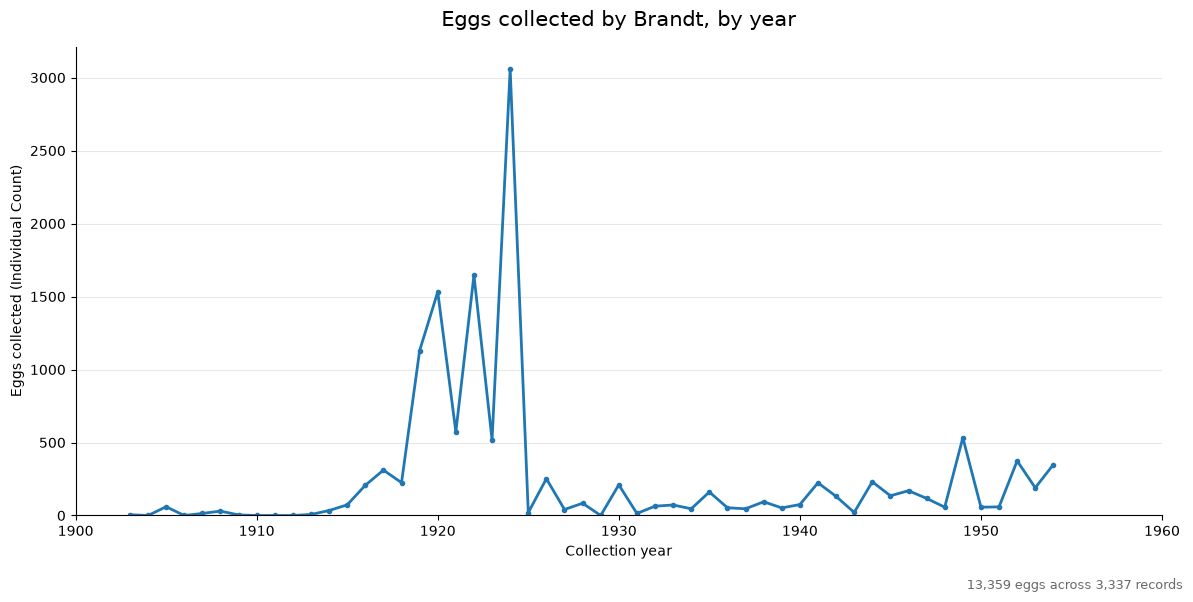

In [4]:
# Sum eggs by year; include zero years so the line spans the full period.
annual = usable.groupby("collection_year")["egg_count"].sum().sort_index()
annual = annual.reindex(range(annual.index.min(), annual.index.max() + 1), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(annual.index, annual.values, color="tab:blue", linewidth=2, marker="o", markersize=3)
ax.set_title("Eggs collected by Brandt, by year", fontsize=15, pad=15)
ax.set_xlabel("Collection year")
ax.set_ylabel("Eggs collected (Individual Count)")
ax.set_ylim(bottom=0)
ax.set_xlim(annual.index.min() - 1, annual.index.max() + 1)
first_decade = (annual.index.min() // 10) * 10
ax.set_xticks(range(first_decade, annual.index.max() + 11, 10))
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.99, 0.01, f"{annual.sum():,} eggs across {len(usable):,} records", ha="right", fontsize=9, color="dimgray")

fig.tight_layout(rect=(0, 0.035, 1, 1))
fig.savefig(OUTPUT_PATH, dpi=200, bbox_inches="tight")
print(f"Saved graph: {OUTPUT_PATH}")
plt.show()
